# code_201 · Interpretability starts with the question and the model

**Book:** section 38.1. Restart and run all cells. Imports, helpers and generated observations are internal; ordinary execution is offline and CPU-only, with no credentials or files. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_38_GUIDE.md), [execution evidence](../CHAPTER_38_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_201).

Reference runtime: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0 and scikit-learn 1.9.0. Allow two minutes to execute and 45–90 minutes to interpret. Explanation contracts identify the fitted function, target output, reference population, permitted perturbations and action limits. Original experiments expose metric behaviour; they are not benchmark reproductions or evidence that the generated law describes inspected structures. Simulator-only truth is labelled separately from observable assessment. No final score chooses a model or threshold. No dependency or asset is added.


In [1]:
import platform,time,json,copy
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn,threadpoolctl
from scipy.special import expit
from IPython.display import display
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
START=time.perf_counter();SEED=8001;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__}
print(VERSIONS);print(platform.system(),platform.machine(),'CPU; seed',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':10,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0'}
Darwin arm64 CPU; seed 8001


<a id="transparent-physical-baselines"></a>
 ## Fit interpretable baselines in a declared representation
 Generate independent 1,200 source and 600 final beams. Visible physical fields are load q(kN/m), span L(m), modulus E(GPa) and inertia I(in units of 10^-4 m^4), plus four irrelevant Gaussian sensors. Correlated log load/span vary by design. The known teaching cantilever law gives deflection 10qL^4/(8EI) mm; observed deflection has independent multiplicative log noise of standard deviation 0.05. Fit raw linear regression, a standardized log-feature Lasso with fixed alpha0.01, a depth-three native tree and a fixed120-iteration histogram booster. The log Lasso predicts log millimetres then exponentiates, so its back-transform is median-like under this law, not an automatically bias-corrected conditional mean. Its physical coefficients describe the chosen model representation; they do not become discovered field mechanisms simply because the generator supplies known exponents.


,RMSE_mm,MAE_mm,negative_prediction_fraction
Raw linear,199.829829,71.372715,0.208333
Log Lasso,14.445465,5.719335,0.000000
Depth3 tree,192.433352,55.572144,0.000000
Boost,146.641885,23.125167,0.010000


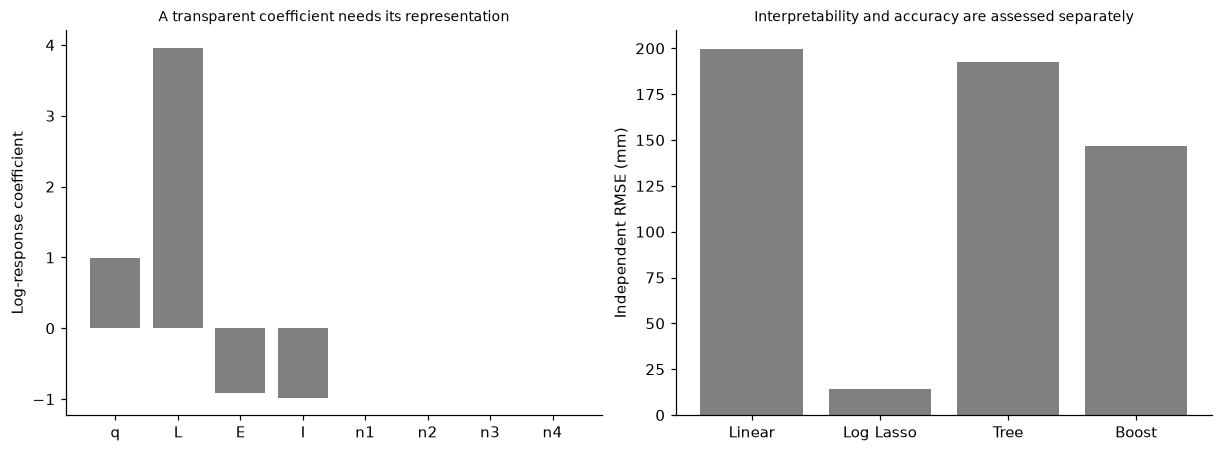

In [2]:
from sklearn.linear_model import LinearRegression,Lasso
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import HistGradientBoostingRegressor
def cohort(n):
    cov=np.diag([.4,.2,.1,.3])@np.array([[1,.85,0,0],[.85,1,0,0],[0,0,1,0],[0,0,0,1]])@np.diag([.4,.2,.1,.3]);logs=rng.multivariate_normal(np.log([20,3,30,1]),cov,size=n);physical=np.exp(logs);q,L,E,I=physical.T;true=10*q*L**4/(8*E*I);y=true*np.exp(rng.normal(scale=.05,size=n));nuisance=rng.normal(size=(n,4));return np.c_[physical,nuisance],np.c_[logs,nuisance],y,true
xs,zs,ys,_=cohort(1200);xf,zf,yf,truth=cohort(600);scaler=StandardScaler().fit(zs);lasso=Lasso(alpha=.01,max_iter=10000).fit(scaler.transform(zs),np.log(ys));raw=LinearRegression().fit(xs,ys);tree=DecisionTreeRegressor(max_depth=3,min_samples_leaf=30,random_state=SEED).fit(xs,ys);boost=HistGradientBoostingRegressor(max_iter=120,max_depth=3,early_stopping=False,random_state=SEED).fit(xs,ys);pred={'Raw linear':raw.predict(xf),'Log Lasso':np.exp(lasso.predict(scaler.transform(zf))),'Depth3 tree':tree.predict(xf),'Boost':boost.predict(xf)};scores={name:{'RMSE_mm':float(np.sqrt(np.mean((p-yf)**2))),'MAE_mm':float(np.mean(abs(p-yf))),'negative_prediction_fraction':float(np.mean(p<0))} for name,p in pred.items()};coefficient=lasso.coef_/scaler.scale_;intercept=float(lasso.intercept_-coefficient@scaler.mean_);assert np.allclose(scaler.mean_,zs.mean(0));assert np.allclose(lasso.predict(scaler.transform(zf)),zf@coefficient+intercept);assert np.all(pred['Log Lasso']>0)
RESULTS.update(source_beams=1200,final_beams=600,physical_log_exponents=[1,4,-1,-1],log_Lasso_coefficients=coefficient.tolist(),log_Lasso_intercept=intercept,zeroed_nuisance_coefficients=int(np.sum(coefficient[4:]==0)),prediction_scores=scores,log_backtransform_not_mean_correction=True);display(pd.DataFrame(scores).T);fig,axes=plt.subplots(1,2,figsize=(11,4));axes[0].bar(np.arange(8),coefficient,color='.5');axes[0].set(xticks=np.arange(8),xticklabels=['q','L','E','I','n1','n2','n3','n4'],ylabel='Log-response coefficient',title='A transparent coefficient needs its representation');axes[1].bar(np.arange(4),[scores[k]['RMSE_mm'] for k in scores],color='.5');axes[1].set(xticks=np.arange(4),xticklabels=['Linear','Log Lasso','Tree','Boost'],ylabel='Independent RMSE (mm)',title='Interpretability and accuracy are assessed separately');plt.show()


<a id="local-trace-and-interpretation-goals"></a>
 ## Trace one prediction without treating it as an action justification
 Use the first fixed final beam. For the log Lasso, decompose the predicted log deflection around mean source transformed features: intercept prediction plus feature contributions. This is an exact explanation of that fitted linear function on the log scale, not a causal attribution in millimetres. For the native depth-three tree, read its actual decision_path and leaf value to reconstruct the conditions taken by that same beam. An engineer inspecting units/model dependence, a developer checking a wrong split, a scientist testing the power law and an auditor checking provenance have different questions. A short path does not verify source labels, feasibility, uncertainty or authorization to act. These traces consume no final truth for model selection.


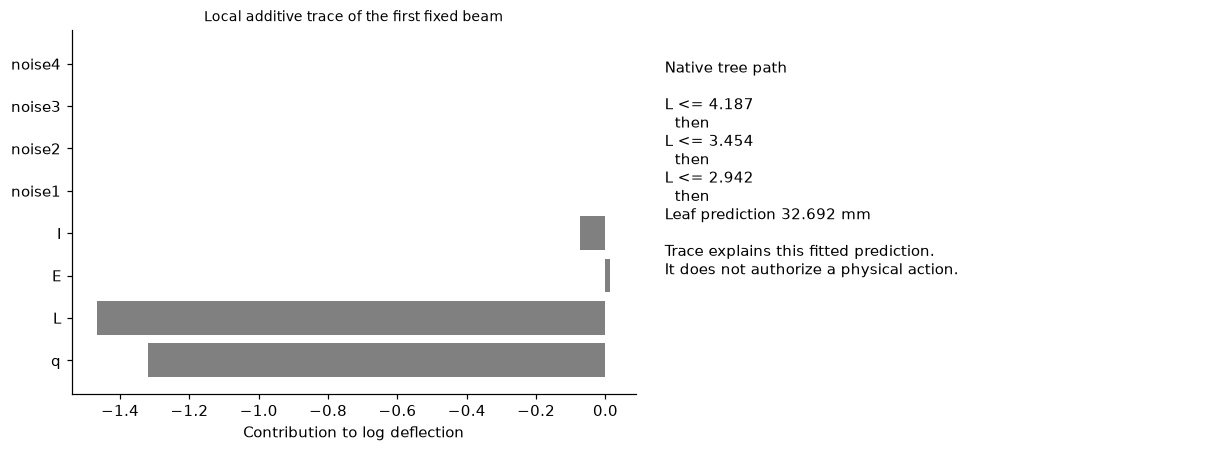

In [3]:
names=['q','L','E','I','noise1','noise2','noise3','noise4'];contribution=lasso.coef_*scaler.transform(zf[:1])[0];base=float(lasso.intercept_);log_prediction=float(lasso.predict(scaler.transform(zf[:1]))[0]);assert np.isclose(base+contribution.sum(),log_prediction);nodes=tree.decision_path(xf[:1]).indices;path=[]
for node in nodes:
    feature=tree.tree_.feature[node]
    if feature>=0:path.append(f'{names[feature]} {"<=" if xf[0,feature]<=tree.tree_.threshold[node] else ">"} {tree.tree_.threshold[node]:.3f}')
    else:path.append(f'Leaf prediction {tree.tree_.value[node].ravel()[0]:.3f} mm')
assert len(path)<=4;assert np.isclose(tree.tree_.value[nodes[-1]].ravel()[0],pred['Depth3 tree'][0]);RESULTS.update(first_final_beam_log_prediction=log_prediction,source_mean_log_baseline=base,first_final_local_log_contributions=contribution.tolist(),native_tree_actual_path=path,final_truth_used_for_explanation_selection=False);fig,axes=plt.subplots(1,2,figsize=(11,4));axes[0].barh(np.arange(8),contribution,color='.5');axes[0].set(yticks=np.arange(8),yticklabels=names,xlabel='Contribution to log deflection',title='Local additive trace of the first fixed beam');axes[1].axis('off');axes[1].text(.03,.92,'Native tree path\n\n'+'\n  then\n'.join(path)+'\n\nTrace explains this fitted prediction.\nIt does not authorize a physical action.',va='top',fontsize=10);plt.show()


In [4]:
summary={'example_id':'code_201','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['actual raw linear log Lasso small tree and boosted physical response models', 'source-only transformed coefficient interpretation with nuisance variables', 'actual local additive log prediction and native tree decision path', 'independent accuracy and negative physical output diagnostics'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["actual raw linear log Lasso small tree and boosted physical response models", "source-only transformed coefficient interpretation with nuisance variables", "actual local additive log prediction and native tree decision path", "independent accuracy and negative physical output diagnostics"], "elapsed_seconds": 0.363, "example_id": "code_201", "hardware": "Darwin arm64 CPU", "results": {"final_beams": 600, "final_truth_used_for_explanation_selection": false, "first_final_beam_log_prediction": 1.3714006798680733, "first_final_local_log_contributions": [-1.3202566510252753, -1.4655285232915092, 0.013358850342218105, -0.07426446816925701, -0.0, -0.0, -0.0, 0.0], "log_Lasso_coefficients": [0.991047717368326, 3.959420204667577, -0.9073450156705507, -0.9782236316879476, 0.0, -0.0, -0.0, -0.0], "log_Lasso_intercept": -0.022041864978050718, "log_backtransform_not_mean_correction": true, "native_tree_actual_path": ["L <= 4.187", "L <= 3.454", "L 